# 09 — Statistics and reproducibility

The three downstream seeds, their dispersion, and the honest limits of what they can support.

**Evidence base**

- `reports/audits/phase29_phase_d_three_seed_descriptive_summary.json`
- `reports/audits/phase29_val808_seedwise_metrics.json`
- `full_doc_report/tables/REMEDFILM_PAIRED_DELTA.json`

> Execution is `ANALYSIS_ONLY`. Training, new inference and protected TEST access
> are blocked by an installed audit hook (verified below).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, r"D:\Softfors\jup\full_doc_report\Scripts")
import remedfilm_guard as GUARD
GUARD.install()

REPO = Path(r"D:\Softfors\jup")
REPORT = REPO / "full_doc_report"
TABLES = REPORT / "tables"
FIG = REPORT / "figures"

import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown

def fig(subdir, name, width=760):
    """Display a generated figure, failing loudly if it is missing."""
    p = FIG / subdir / f"{name}.png"
    if not p.exists():
        raise FileNotFoundError(f"missing figure: {p}")
    display(Image(filename=str(p), width=width))

def table(path, **kw):
    return pd.read_csv(path, **kw)

GUARD.require()

True

In [2]:
# Negative control — enforcement must be real, not a flag.
for name, verdict in GUARD.self_test():
    print(f"  {name:28s}: {verdict}")
assert all(v.startswith("blocked") for _, v in GUARD.self_test()), "GUARD FAILED"
print("analysis-only guard verified")

  optimiser construction      : blocked
  AdamW construction          : blocked
  TEST manifest read          : blocked
  write outside report dir    : blocked
analysis-only guard verified


## 9.1 Seed-wise summary

In [3]:
d = json.loads((REPO / "reports/audits/phase29_phase_d_three_seed_descriptive_summary.json").read_text(encoding="utf-8"))
rows = []
for m in d["per_metric"]:
    rows.append({"metric": m["metric"], "seed42": m["seed42"], "seed123": m["seed123"],
                 "seed3407": m["seed3407"], "mean": m["mean"],
                 "sd": m["sample_sd_ddof1"], "range": m["range"],
                 "sign_consistent": m["sign_consistent"]})
pd.DataFrame(rows).round(8)

,metric,seed42,seed123,seed3407,mean,sd,range,sign_consistent
0,macro_final_dice,0.837289,0.838467,0.837948,0.837901,0.000590,0.001178,True
1,macro_global_dice,0.835079,0.835079,0.835079,0.835079,0.000000,0.000000,True
2,macro_delta_dice,0.002210,0.003388,0.002869,0.002822,0.000590,0.001178,True
3,n_selected,279.000000,255.000000,262.000000,265.333333,12.342339,24.000000,True
4,selected_fraction,0.345297,0.315594,0.324257,0.328383,0.015275,0.029703,True
5,n_accepted,266.000000,230.000000,256.000000,250.666667,18.583146,36.000000,True
6,safety_accept_fraction,0.953405,0.901961,0.977099,0.944155,0.038414,0.075138,True
7,n_final_refined,266.000000,230.000000,256.000000,250.666667,18.583146,36.000000,True


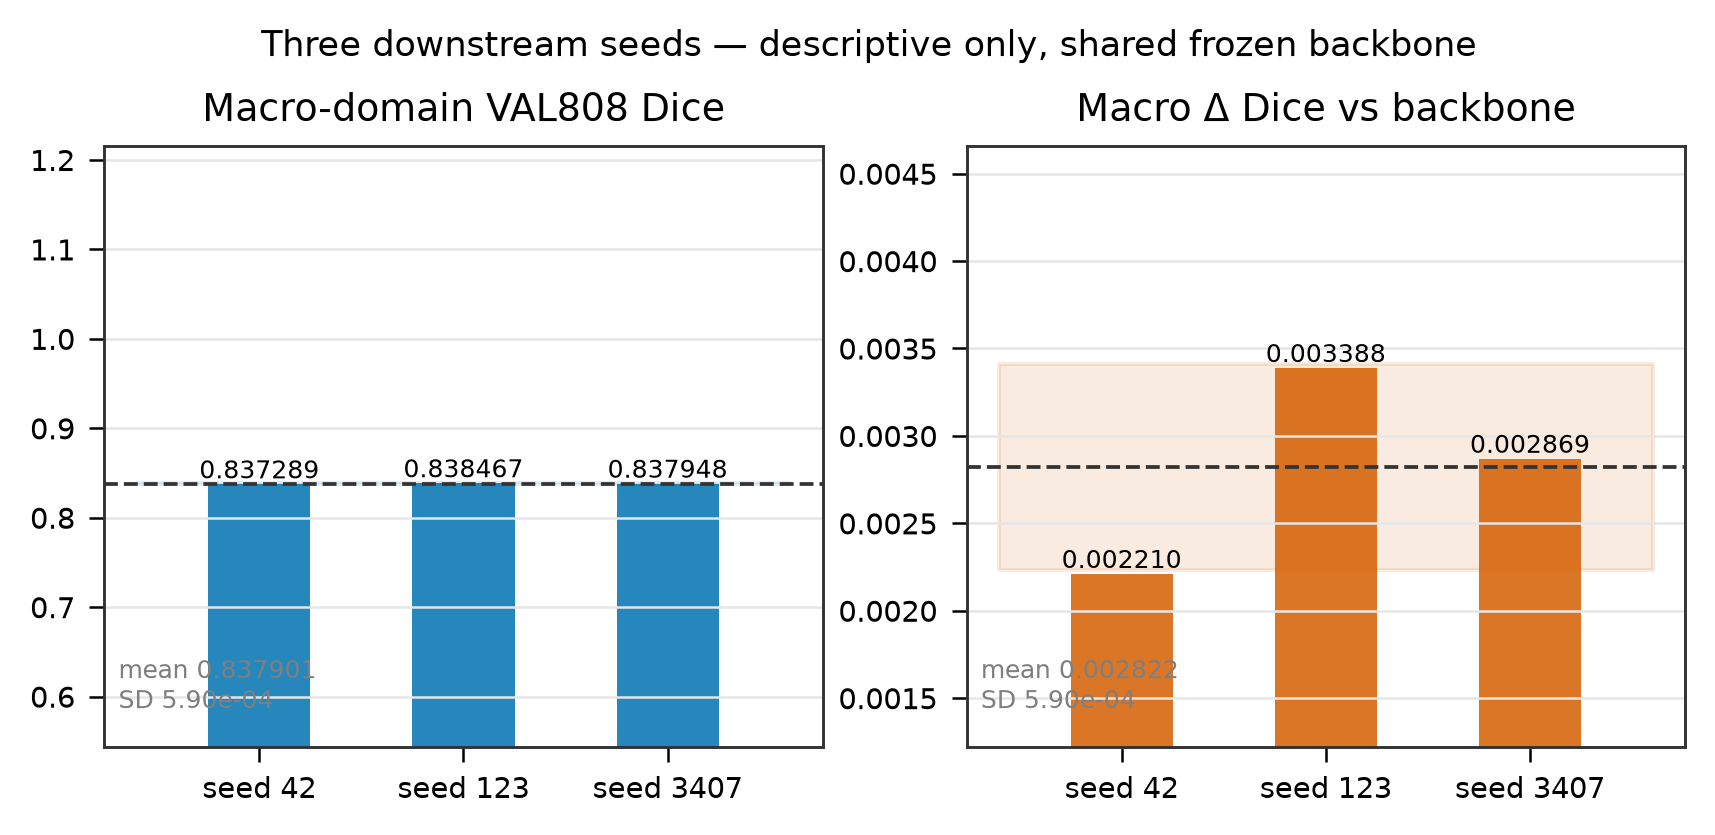

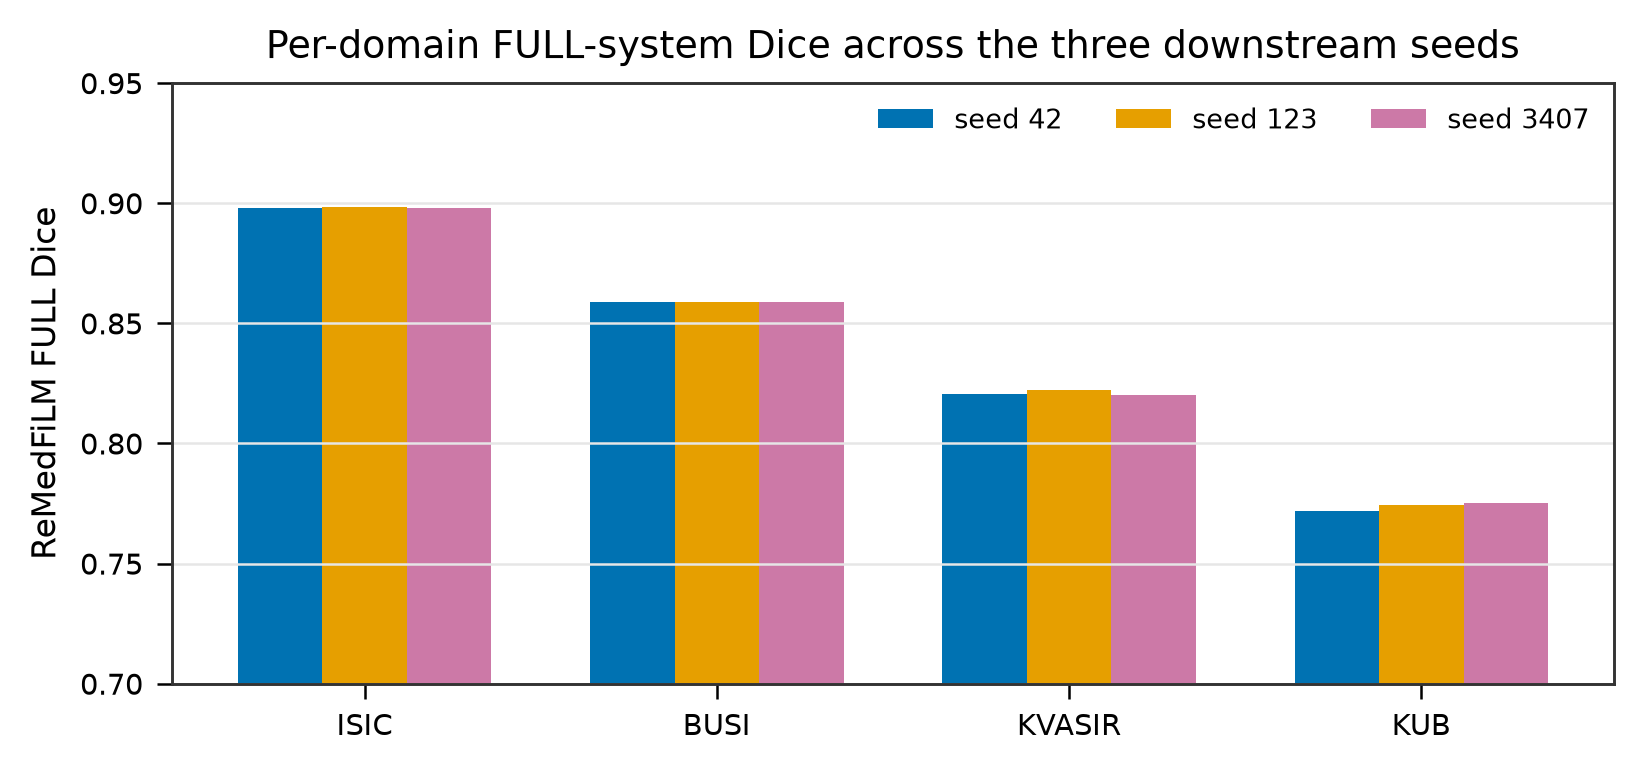

In [4]:
fig("Statistics", "STAT01_seedwise_macro_metrics", width=760)
fig("Statistics", "STAT03_seedwise_per_domain", width=700)

## 9.2 The bootstrap interval

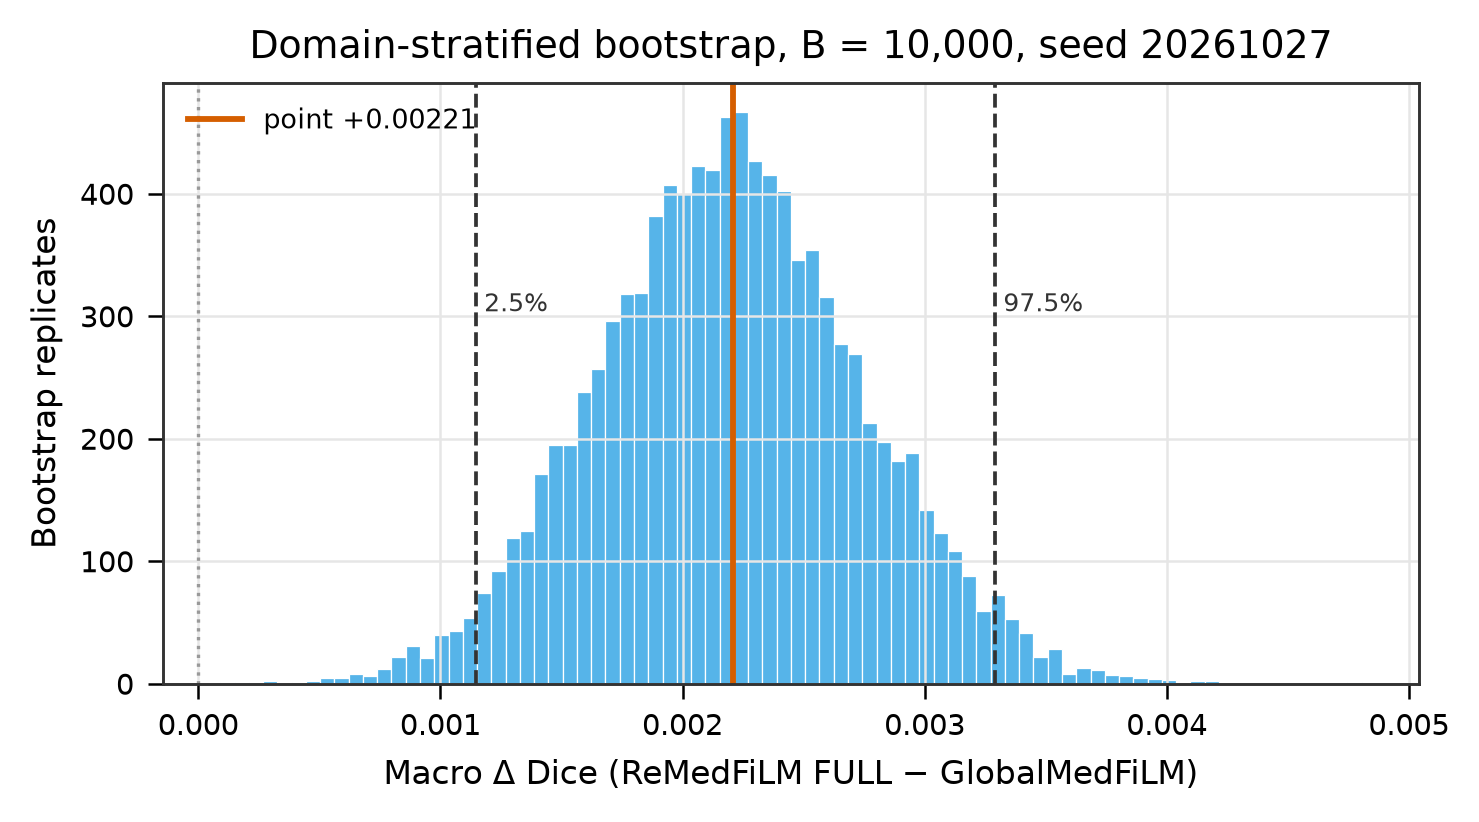

In [5]:
fig("Statistics", "STAT02_bootstrap_distribution", width=620)

In [6]:
pd_ = json.loads((TABLES / "REMEDFILM_PAIRED_DELTA.json").read_text(encoding="utf-8"))
print("VAL808 paired macro delta:", f"{pd_['point']:+.8f}",
      f"[{pd_['ci_low']:+.8f}, {pd_['ci_high']:+.8f}]")
print("B =", pd_["n_boot"], "seed", pd_["seed"], "| method:", pd_["method"])

VAL808 paired macro delta: +0.00220997 [+0.00114769, +0.00329205]
B = 10000 seed 20261027 | method: domain-stratified percentile bootstrap over images


## 9.3 What the three seeds actually are

`macro_global_dice` is identical to machine precision across seeds
(SD ≈ 1.4×10⁻¹⁶), which proves the backbone was **shared and frozen**.
Only R_psi, B_phi and S_omega were re-fitted.

Therefore:

* the seeds measure **downstream component stability**, not end-to-end reproducibility;
* they cannot be described as three independent training runs;
* no p-value is computed, and none should be.

In [7]:
g = [m for m in d["per_metric"] if m["metric"] == "macro_global_dice"][0]
print("macro_global_dice across seeds:", g["seed42"], g["seed123"], g["seed3407"])
print("sample SD:", g["sample_sd_ddof1"])
print("-> identical backbone confirmed")

macro_global_dice across seeds: 0.8350789601074979 0.8350789601074979 0.8350789601074979
sample SD: 1.3597399555105182e-16
-> identical backbone confirmed


## 9.4 Population accounting

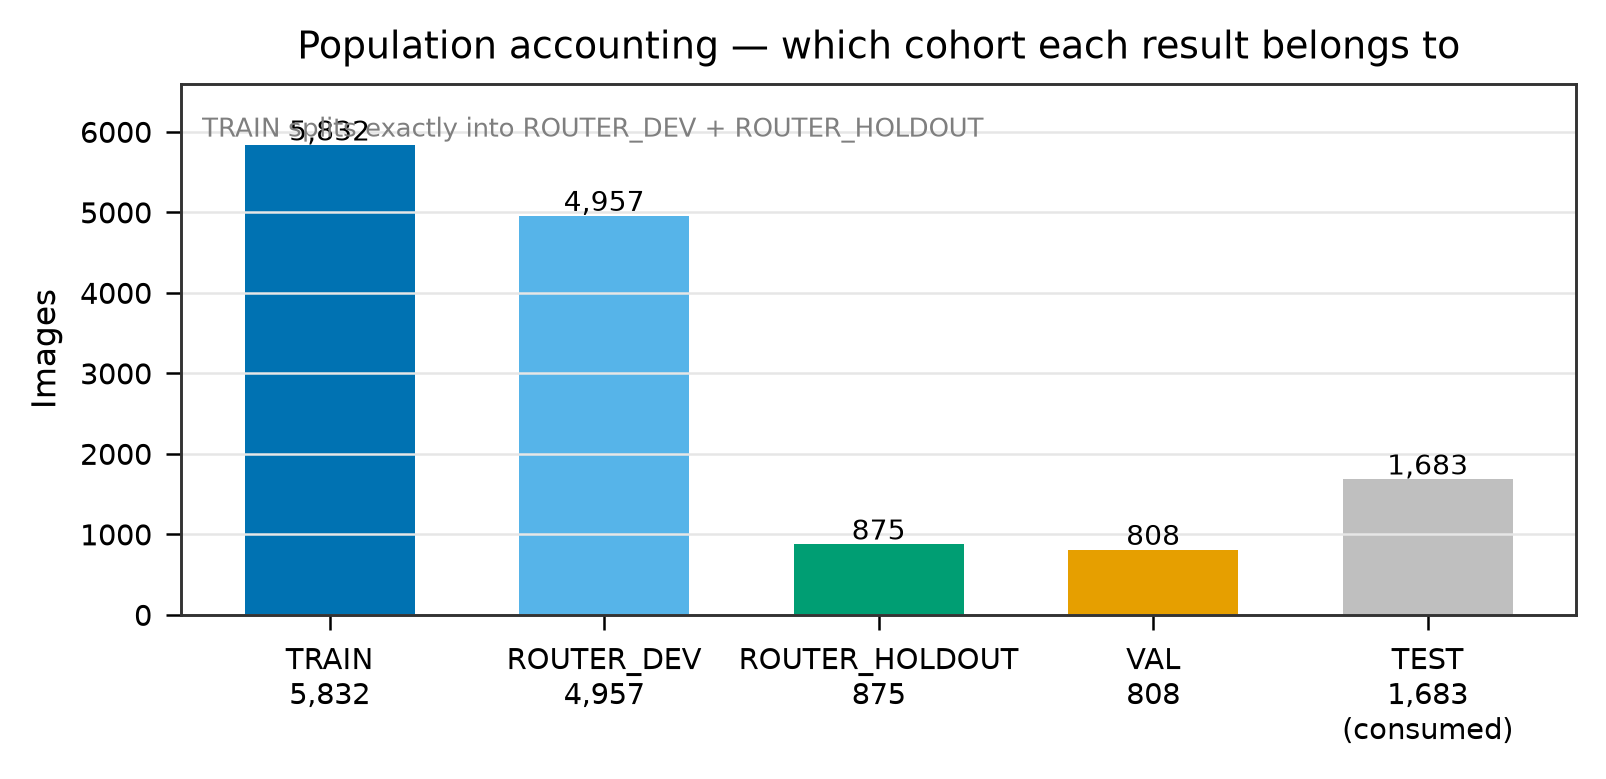

In [8]:
fig("Statistics", "STAT04_population_accounting", width=640)

In [9]:
# Negative control — enforcement must be real, not a flag.
for name, verdict in GUARD.self_test():
    print(f"  {name:28s}: {verdict}")
assert all(v.startswith("blocked") for _, v in GUARD.self_test()), "GUARD FAILED"
print("analysis-only guard verified")

  optimiser construction      : blocked
  AdamW construction          : blocked
  TEST manifest read          : blocked
  write outside report dir    : blocked
analysis-only guard verified
